# BAQ-TD
Run the cells from top to bottom, or choose **Runtime > Run all**.
The notebook is self-contained and requires no uploaded dataset or source files.

1. **ECC-1:** quantization precision (10, 12, 16 bits and unquantized TD).
2. **ECC-2:** batch sizes 512, 2048, and 8192.
3. **ECC-3:** terminal error versus sample budget, 12/16 bits and unquantized TD.

All figures use the same **8 by 5 inch canvas**, **300-dpi PNG export**, vector
PDF export, bold logarithmic ticks, internal boxed legend, and inset style.
Exported PNGs contain a DPI tag and no software text tag.

## Source and reproducibility

The model, sampling, midpoint codec, and update code were recovered from
`BAQ_TD_Experiments.zip` / `BAQ_TD_Tabular_Experiments.ipynb`.
The archive contains 10-trial data with K=2000 and H=2048; its batch sweep
used m=12. Later plot reformatting used supplied raster curves, whose exact
raw simulation data were not recovered. Consequently this notebook does
**not** promise the precise numerical legend values in those later images.
Every displayed value is recomputed from the actual trials.

The visible settings below use 100 trials, the archived precision setup, and
the later batch caption's K=1000, m=16. The sample-budget experiment adds
m=16 to the archived matched-batch comparison. All settings are editable.

**Error definition:** the recovered simulator stores squared parameter error.
`ERROR_METRIC="l2"` plots the Euclidean error requested in later captions,
converting each trial before averaging. Set it to `"squared_l2"` to plot
the historical squared-error statistic; the budget guide then becomes 1/T.

**Radius version:** `RADIUS_RULE="archive"` preserves the historical update.
Select `"current_manuscript"` for the revised C_delta and 2*alpha drift rule.
The practical stepsize and batch sizes are empirical settings and do not
impose every sufficient condition in the theorem.


In [ ]:
%pip -q install numpy scipy pandas matplotlib threadpoolctl


In [ ]:
import json, time, platform, csv, shutil, zipfile, argparse
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, NullFormatter
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

# EDIT THESE SETTINGS BEFORE RUNNING.
OUT = Path("baq_td_three_plots")
MODEL_SEED = 20261013
N_STATES, N_ACTIONS, N_FEATURES = 100, 4, 10
GAMMA, ALPHA, DELTA = 0.5, 0.1, 0.05
N_TRIALS = 100
SIGMA = 1.0
# Preserve the recovered implementation by default. Select
# "current_manuscript" to use the revised C_delta and 2*alpha drift rule.
RADIUS_RULE = "archive"     # "archive" or "current_manuscript"
PRECISION_K, PRECISION_H = 2000, 2048
BATCH_K, BATCH_BITS = 1000, 16
BIT_LEVELS = (10, 12, 16)
BATCH_LEVELS = (512, 2048, 8192)
BUDGETS = 2 ** np.array([16, 18, 20, 22, 24])
EPOCH_COEFFICIENT = 200.0

# Current captions use Euclidean error. The archived simulator stores
# squared errors. Conversion is applied to EACH trial before averaging.
ERROR_METRIC = "l2"          # "l2" or "squared_l2"
SHADED_BAND = "sd"          # "sd" or "se"
FIGSIZE, DPI = (8, 5), 300
SAVE_PDF = True
SHOW_FIGURES = False


## Recovered simulator



In [ ]:
def make_mdp(seed=MODEL_SEED, n=N_STATES, n_actions=N_ACTIONS, d=N_FEATURES):
    rng = np.random.default_rng(seed)
    Pa = np.zeros((n_actions, n, n))
    for a in range(n_actions):
        for s in range(n):
            Pa[a, s, s] += 0.2
            Pa[a, s, (s + 1) % n] += 0.2
            destinations = rng.choice(n, 4, replace=False)
            Pa[a, s, destinations] += 0.6 * rng.dirichlet(np.ones(4))
    P = Pa.mean(axis=0)
    L = P.T - np.eye(n)
    L[-1] = 1.0
    rhs = np.zeros(n); rhs[-1] = 1.0
    nu = np.linalg.solve(L, rhs)
    assert np.all(nu > 0) and np.allclose(nu @ P, nu)
    Phi = rng.choice([-1.0, 1.0], (n, d)) / np.sqrt(d)
    Phi[:, 0] = 1.0 / np.sqrt(d)
    reward_mean = rng.uniform(0, 5, n)
    return attach_features(P, nu, reward_mean, Phi, Pa=Pa)


def attach_features(P, nu, reward_mean, Phi, Pa=None):
    n, d = Phi.shape
    assert np.linalg.matrix_rank(Phi) == d
    assert np.max(np.linalg.norm(Phi, axis=1)) <= 1 + 1e-12
    D = Phi.T @ (nu[:, None] * Phi)
    A = Phi.T @ (nu[:, None] * (Phi - GAMMA * (P @ Phi)))
    b = Phi.T @ (nu * reward_mean)
    theta_star = np.linalg.solve(A, b)
    src, dst = np.nonzero(P)
    joint = nu[src] * P[src, dst]
    joint /= joint.sum()
    tabular = d == n and np.array_equal(Phi, np.eye(n))
    edge_A = None if tabular else np.einsum(
        'ei,ej->eij', Phi[src], Phi[src] - GAMMA * Phi[dst]
    ).reshape(len(src), d*d)
    return dict(P=P, Pa=Pa, nu=nu, reward_mean=reward_mean, Phi=Phi,
                D=D, A=A, b=b, theta_star=theta_star, n=n, d=d,
                omega=(1-GAMMA)*np.linalg.eigvalsh(D)[0], beta=1+GAMMA,
                rbar=5.0, src=src, dst=dst, joint=joint, edge_A=edge_A,
                tabular=tabular)


def allowance(mod, K, H, sigma):
    d = mod['d']
    if RADIUS_RULE == 'archive':
        C2 = 2 * max(mod['beta']**2*d**2, d*(mod['rbar']**2+sigma**2)) * np.log(4*K*d*d/DELTA)
    elif RADIUS_RULE == 'current_manuscript':
        C2 = 2 * max(64, d*(mod['rbar']**2+sigma**2)) * np.log(4*K*d/DELTA)
    else:
        raise ValueError("Unknown RADIUS_RULE.")
    return C2, np.sqrt(C2/H)


def encode(u, R, m):
    """Radial saturation followed by the manuscript's right-bin midpoint indices."""
    if R == 0:
        return np.zeros(u.size, dtype=np.int64), np.zeros_like(u)
    v = u * min(1.0, R/max(np.linalg.norm(u), np.finfo(float).tiny))
    levels = 2**m
    indices = np.floor(levels*(v+R)/(2*R)).astype(np.int64)
    return np.clip(indices, 0, levels-1), v


def decode(indices, R, m):
    if R == 0:
        return np.zeros(indices.size)
    return -R + (2*indices+1)*R/(2**m)


@dataclass(frozen=True)
class Method:
    label: str
    kind: str = 'baq'    # 'baq', 'unquantized', or 'fixed'
    m: int = 12


def batch_stream(mod, K, H, sigma, seed, block=64):
    rng = np.random.default_rng(seed)
    n, d = mod['n'], mod['d']
    src, dst = mod['src'], mod['dst']
    for start in range(0, K, block):
        size = min(block, K-start)
        counts = rng.multinomial(H, mod['joint'], size=size)
        state_counts = np.zeros((size,n))
        for j in range(size):
            state_counts[j] = np.bincount(src, weights=counts[j], minlength=n)
        reward_sums = (state_counts*mod['reward_mean'] +
                       sigma*np.sqrt(state_counts)*rng.standard_normal((size,n)))
        bhat = reward_sums @ mod['Phi'] / H
        if mod['tabular']:
            ahat = np.zeros((size,n,n))
            ahat[:,src,dst] = -GAMMA * counts / H
            diag = np.arange(n)
            ahat[:,diag,diag] += state_counts/H
        else:
            ahat = (counts @ mod['edge_A']).reshape(size,d,d) / H
        for j in range(size):
            yield ahat[j], bhat[j]


def direct_tuple_check(mod):
    rng=np.random.default_rng(671)
    H=113
    edges=rng.choice(len(mod['src']),size=H,p=mod['joint'])
    s,sp=mod['src'][edges],mod['dst'][edges]
    r=mod['reward_mean'][s]+rng.normal(size=H)
    theta=rng.normal(size=mod['d'])
    phi,phip=mod['Phi'][s],mod['Phi'][sp]
    y=phi.T@(r+GAMMA*(phip@theta)-phi@theta)/H
    counts=np.bincount(edges,minlength=len(mod['src']))
    ahat=(counts@mod['edge_A']).reshape(mod['d'],mod['d'])/H
    bhat=mod['Phi'].T@np.bincount(s,weights=r,minlength=mod['n'])/H
    assert np.allclose(y,bhat-ahat@theta,atol=1e-12)
    # Sanity check that the count sampler targets the intended operator.
    means=list(batch_stream(mod,200,2048,1.0,2718))
    Amean=np.mean([a for a,b in means],axis=0)
    bmean=np.mean([b for a,b in means],axis=0)
    assert np.linalg.norm(Amean-mod['A'])<.02
    assert np.linalg.norm(bmean-mod['b'])<.03
    return np.linalg.norm(Amean-mod['A']),np.linalg.norm(bmean-mod['b'])


def parameter_audit(mod, K, H, sigma, alpha, m):
    C2, eps = allowance(mod,K,H,sigma)
    omega=mod['omega']; m_min=int(np.ceil(.5*np.log2(64*mod['d']/omega)))
    return dict(d=mod['d'], K=K,H=H,sigma2=sigma*sigma,alpha=alpha,m=m,
                epsilon_H=eps,alpha_sufficient_max=omega/32,m_sufficient_min=m_min,
                H_sufficient_min=int(np.ceil(1024*C2/omega**2)),
                stepsize_condition=alpha<=omega/32,precision_condition=m>=m_min,
                batch_condition=H>=1024*C2/omega**2)


def run_group(mod, methods, K, H, sigma=1., alpha=ALPHA, trials=N_TRIALS, seed=1000):
    C2, eps=allowance(mod,K,H,sigma)
    d=mod['d']; theta0=np.zeros(d)
    drift_coefficient = mod['beta'] if RADIUS_RULE == 'archive' else 2.
    R0=mod['rbar']+drift_coefficient*np.linalg.norm(theta0)+eps*(np.linalg.norm(theta0)+1)
    results={m.label:dict(mse=np.full((trials,K+1),np.nan),
                         value_error=np.full((trials,K+1),np.nan),
                         radius=np.full((trials,K+1),np.nan),
                         innovation_ratio=np.full((trials,K),np.nan),
                         reconstruction_ratio=np.full((trials,K),np.nan),
                         saturation=np.zeros((trials,K),dtype=bool),
                         kind=m.kind,m=m.m,K=K,H=H,alpha=alpha,sigma=sigma,
                         d=d,epsilon_H=eps,C2=C2,seed=seed,failed_trials=[]) for m in methods}
    concentration_max=np.zeros((trials,2))
    started=time.perf_counter()
    for trial in range(trials):
        if trial % max(1, trials//10) == 0:
            print(f"  trial {trial+1}/{trials}", flush=True)
        theta=np.tile(theta0,(len(methods),1)); h=np.zeros_like(theta)
        radii=np.full(len(methods),R0); active=np.ones(len(methods),dtype=bool)
        for j,m in enumerate(methods):
            r=results[m.label];r['mse'][trial,0]=np.sum((theta[j]-mod['theta_star'])**2)
            r['value_error'][trial,0]=np.max(np.abs(mod['Phi']@(theta[j]-mod['theta_star'])))
            r['radius'][trial,0]=R0 if m.kind!='unquantized' else np.nan
        for k,(ahat,bhat) in enumerate(batch_stream(mod,K,H,sigma,seed+trial)):
            concentration_max[trial]=np.maximum(concentration_max[trial],
                [np.linalg.norm(ahat-mod['A'],'fro')/eps,np.linalg.norm(bhat-mod['b'])/eps])
            for j,m in enumerate(methods):
                if not active[j]: continue
                r=results[m.label];old_theta=theta[j].copy()
                Y=bhat-ahat@old_theta
                if m.kind=='unquantized':
                    new_h=Y
                else:
                    eta=np.sqrt(d)/2**m.m
                    u=Y-h[j] if m.kind=='baq' else Y
                    R=radii[j]
                    r['innovation_ratio'][trial,k]=np.linalg.norm(u)/max(R,np.finfo(float).tiny)
                    r['saturation'][trial,k]=np.linalg.norm(u)>R*(1+1e-12)
                    indices,_=encode(u,R,m.m)
                    decoded=decode(indices,R,m.m)
                    new_h=h[j]+decoded if m.kind=='baq' else decoded
                    r['reconstruction_ratio'][trial,k]=np.linalg.norm(new_h-Y)/max(eta*R,np.finfo(float).tiny)
                    if m.kind=='baq':
                        radii[j]=eta*R+alpha*drift_coefficient*np.linalg.norm(new_h)+2*eps*(np.linalg.norm(old_theta)+1)
                theta[j]=old_theta+alpha*new_h;h[j]=new_h
                if not np.all(np.isfinite(theta[j])) or np.linalg.norm(theta[j])>1e40:
                    active[j]=False;r['failed_trials'].append(trial);continue
                e=theta[j]-mod['theta_star']
                r['mse'][trial,k+1]=e@e
                r['value_error'][trial,k+1]=np.max(np.abs(mod['Phi']@e))
                if m.kind!='unquantized': r['radius'][trial,k+1]=radii[j]
    for r in results.values():
        r['concentration_max']=concentration_max.copy()
        if r['kind']=='baq':
            valid=(~r['saturation']) & np.isfinite(r['reconstruction_ratio'])
            assert np.all(r['reconstruction_ratio'][valid] <= 1+1e-8)
    print(f"K={K}, H={H}, sigma²={sigma*sigma:g}, d={d}: {time.perf_counter()-started:.1f}s",flush=True)
    return results


def summary_table(results):
    rows=[]
    for name,r in results.items():
        last=r['mse'][:,-1]
        quant=r['kind']!='unquantized'
        rows.append(dict(method=name,mean_final_mse=last.mean(),
            se_final_mse=last.std(ddof=1)/np.sqrt(len(last)),
            mean_final_value_sup_error=r['value_error'][:,-1].mean(),
            saturated_epochs=int(r['saturation'].sum()),
            max_innovation_ratio=np.nanmax(r['innovation_ratio']) if quant else np.nan,
            max_reconstruction_ratio=np.nanmax(r['reconstruction_ratio']) if quant else np.nan,
            sufficient_G_certified_trials=int(np.sum(np.max(r['concentration_max'],axis=1)<=1)),
            failed_trials=len(r['failed_trials']), samples=r['K']*r['H'],messages=r['K'],
            uplink_bits=r['K']*r['d']*r['m'] if quant else np.nan))
    return pd.DataFrame(rows)


def save_results(tag,results):
    arrays={}
    metadata={}
    for i,(name,r) in enumerate(results.items()):
        metadata[str(i)]={'label':name,**{k:v for k,v in r.items() if not isinstance(v,np.ndarray)}}
        for k,v in r.items():
            if isinstance(v,np.ndarray): arrays[f'method{i}_{k}']=v
    np.savez_compressed(OUT/f'{tag}_raw.npz',**arrays)
    (OUT/f'{tag}_metadata.json').write_text(json.dumps(metadata,indent=2))
    summary_table(results).to_csv(OUT/f'{tag}_summary.csv',index=False)



## Experiments



In [ ]:
def error_values(result):
    values = np.maximum(result['mse'], 0)
    if ERROR_METRIC == 'l2':
        return np.sqrt(values)
    if ERROR_METRIC == 'squared_l2':
        return values
    raise ValueError("ERROR_METRIC must be 'l2' or 'squared_l2'")


def mean_band(values):
    mean = values.mean(axis=0)
    band = values.std(axis=0, ddof=1)
    if SHADED_BAND == 'se':
        band /= np.sqrt(len(values))
    elif SHADED_BAND != 'sd':
        raise ValueError("SHADED_BAND must be 'sd' or 'se'")
    return mean, band


def configure_style():
    plt.rcParams.update({
        'font.family': 'DejaVu Sans',
        'mathtext.fontset': 'dejavusans',
        'font.weight': 'bold',
        'axes.linewidth': 1.4,
        'axes.labelweight': 'normal',
        'axes.axisbelow': True,
        'xtick.labelsize': 17,
        'ytick.labelsize': 17,
        'xtick.major.width': 1.4,
        'ytick.major.width': 1.4,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'savefig.dpi': DPI,
        'path.simplify': False,
    })


def axes_style(ax, xlabel, ylabel):
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(xlabel, fontsize=29, labelpad=3)
    ax.set_ylabel(ylabel, fontsize=29, labelpad=3)
    ax.grid(which='major', color='#bdbdbd', ls='--', lw=1.15, alpha=.75)
    ax.grid(which='minor', color='#d8d8d8', ls='--', lw=.7, alpha=.65)
    ax.tick_params(which='major', length=6, pad=4)
    ax.tick_params(which='minor', length=3)
    for axis in [ax.xaxis, ax.yaxis]:
        axis.set_major_locator(LogLocator(base=10, numticks=8))
        axis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
        axis.set_minor_formatter(NullFormatter())


def legend_box(ax, entries, subtitle, bounds, heading='BAQ-TD'):
    """A reference-style legend. Every numerical value comes from the run."""
    box = ax.inset_axes(bounds, zorder=20)
    box.set_facecolor('white')
    box.set_xticks([])
    box.set_yticks([])
    for spine in box.spines.values():
        spine.set_linewidth(1.25)
    box.text(.5, .90, heading, ha='center', va='center', color='red',
             weight='bold', fontsize=20)
    if subtitle:
        box.text(.5, .72, subtitle, ha='center', va='center',
                 fontsize=9.8, weight='bold')
    y = np.linspace(.52 if subtitle else .68, .10, len(entries))
    for yy, (label, color, linestyle, marker) in zip(y, entries):
        box.add_line(Line2D([.065, .255], [yy, yy], color=color,
                           ls=linestyle, marker=marker, lw=2.6, ms=4.7,
                           transform=box.transAxes))
        box.text(.29, yy, label, ha='left', va='center',
                 fontsize=10.4, weight='normal')
    return box


def save_figure(fig, stem):
    OUT.mkdir(parents=True, exist_ok=True)
    # No bbox_inches='tight': keep identical physical dimensions for all plots.
    png = OUT / (stem + '.png')
    fig.savefig(png, dpi=DPI, facecolor='white', bbox_inches=None,
                metadata={'Software': None})
    if SAVE_PDF:
        fig.savefig(OUT / (stem + '.pdf'), facecolor='white', bbox_inches=None,
                    metadata={'Creator': '', 'Producer': ''})
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)
    return png


def epoch_plot(results, styles, stem, subtitle):
    configure_style()
    fig = plt.figure(figsize=FIGSIZE, dpi=DPI)
    ax = fig.add_axes([.17, .19, .81, .785])
    K = next(iter(results.values()))['K']
    x = np.arange(1, K + 1)
    axes_style(ax, r'$k$', r'$E_k$')
    ax.set_xlim(1, K)
    entries = []
    inset = ax.inset_axes([.035, .48, .46, .235], zorder=10)
    inset.set_yscale('log')
    inset.set_title('Final 20%', fontsize=12.4, weight='bold', pad=4)
    inset.set_xticks([])
    inset.set_yticks([])
    inset.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    first_late = int(.8 * K)
    means = []
    for key, label, color, linestyle, marker in styles:
        values = error_values(results[key])[:, 1:]
        mean, band = mean_band(values)
        means.append(mean)
        marks = np.unique(np.geomspace(1, K, min(K, 21)).astype(int)) - 1
        ax.plot(x, mean, color=color, ls=linestyle, marker=marker,
                markevery=marks, lw=2.6, ms=5)
        ax.fill_between(x, np.maximum(mean-band, mean*.01), mean+band,
                        color=color, alpha=.10, lw=0)
        inset.plot(x[first_late:], mean[first_late:], color=color,
                   ls=linestyle, lw=1.65)
        inset.fill_between(x[first_late:],
                           np.maximum(mean[first_late:]-band[first_late:],
                                      mean[first_late:]*.01),
                           mean[first_late:]+band[first_late:],
                           color=color, alpha=.09, lw=0)
        late_error = values[:, first_late:].mean()
        entries.append((label + f': {late_error:.4g}', color, linestyle, marker))
    joined = np.concatenate(means)
    ax.set_ylim(joined.min()*.6, joined.max()*1.4)
    inset.set_xlim(x[first_late], K)
    for spine in inset.spines.values():
        spine.set_linewidth(1.2)
    height = .36 if len(styles) == 4 else .32
    legend_box(ax, entries, subtitle, [.035, .025, .50, height])
    return save_figure(fig, stem)


def sample_budget_plot(budget_results):
    configure_style()
    fig = plt.figure(figsize=FIGSIZE, dpi=DPI)
    ax = fig.add_axes([.17, .19, .81, .785])
    axes_style(ax, r'$T$', r'$E_K$')
    requested = np.array(sorted(budget_results))
    xx = np.array([next(iter(budget_results[int(cap)].values()))['K']
                   * next(iter(budget_results[int(cap)].values()))['H']
                   for cap in requested])
    styles = [
        ('BAQ-TD m=12', r'$m=12$', '#e6194b', '--', None),
        ('BAQ-TD m=16', r'$m=16$', '#556b2f', '-.', '^'),
        ('Unquantized TD', 'Unquantized TD', '#222222', ':', None),
    ]
    inset = ax.inset_axes([.61, .64, .36, .23], zorder=10)
    inset.set_xscale('log')
    inset.set_yscale('log')
    inset.set_title('Accuracy zoom', fontsize=12.1, weight='bold', pad=4)
    inset.set_xticks([])
    inset.set_yticks([])
    for axis in [inset.xaxis, inset.yaxis]:
        axis.set_minor_locator(matplotlib.ticker.NullLocator())
    entries = []
    values_for_limits = []
    for key, label, color, linestyle, marker in styles:
        values = np.stack([error_values(budget_results[int(cap)][key])[:, -1]
                           for cap in requested], axis=1)
        mean, band = mean_band(values)
        values_for_limits.append(mean)
        ax.plot(xx, mean, color=color, ls=linestyle, marker=marker,
                ms=6, lw=2.7)
        ax.fill_between(xx, np.maximum(mean-band, mean*.01), mean+band,
                        color=color, alpha=.09, lw=0)
        count = min(3, len(xx))
        inset.plot(xx[-count:], mean[-count:], color=color,
                   ls=linestyle, marker=marker, ms=3.5, lw=1.7)
        entries.append((label+f': {mean[-1]:.4g}', color, linestyle, marker))
    # A shape guide, not a fitted rate or a theorem-derived confidence bound.
    exponent = .5 if ERROR_METRIC == 'l2' else 1.
    reference = values_for_limits[-1][0] * (xx[0] / xx)**exponent
    ax.plot(xx, reference, color='#999999', ls='--', lw=2.3, zorder=1)
    ref_label = r'$1/\sqrt{T}$ reference' if exponent == .5 else r'$1/T$ reference'
    entries.append((ref_label, '#999999', '--', None))
    lower = min(float(np.min(v)) for v in values_for_limits)
    upper = max(float(np.max(v)) for v in values_for_limits)
    ax.set_xlim(xx[0]*.78, xx[-1]*1.18)
    ax.set_ylim(lower*.5, upper*1.5)
    legend_box(ax, entries, 'Bits per coordinate:terminal error',
               [.025, .025, .47, .39])
    return save_figure(fig, 'ECC-3')


def write_computed_statistics(tag, results):
    rows = []
    for label, r in results.items():
        values = error_values(r)
        start = 1 + int(.8*r['K'])
        trial_tail = values[:, start:].mean(axis=1)
        rows.append({
            'method': label, 'metric': ERROR_METRIC, 'trials': len(values),
            'K': r['K'], 'H': r['H'], 'T_used': r['K']*r['H'],
            'terminal_mean': values[:, -1].mean(),
            'terminal_sd': values[:, -1].std(ddof=1),
            'last20pct_mean': trial_tail.mean(),
            'last20pct_sd': trial_tail.std(ddof=1),
            'clipped_epochs': int(r['saturation'].sum()),
            'uplink_bits': '' if r['kind']=='unquantized' else r['K']*r['d']*r['m'],
        })
    pd.DataFrame(rows).to_csv(OUT / f'{tag}_plotted_statistics.csv', index=False)
    return pd.DataFrame(rows)


def run_all():
    if N_TRIALS < 2:
        raise ValueError('Use at least two trials to estimate variability.')
    OUT.mkdir(parents=True, exist_ok=True)
    model = make_mdp()
    direct_tuple_check(model)
    np.savez_compressed(OUT/'mdp.npz', P=model['P'], nu=model['nu'],
                        Phi=model['Phi'], reward_mean=model['reward_mean'],
                        A=model['A'], b=model['b'], theta_star=model['theta_star'])
    print('Figure 1: precision', flush=True)
    precision_methods = [Method(f'BAQ-TD m={m}', m=m) for m in BIT_LEVELS]
    precision_methods += [Method('Unquantized TD', 'unquantized')]
    precision = run_group(model, precision_methods, PRECISION_K, PRECISION_H,
                          sigma=SIGMA, trials=N_TRIALS, seed=10000)
    save_results('precision', precision)
    print(write_computed_statistics('precision', precision).to_string(index=False))
    epoch_plot(precision, [
        ('BAQ-TD m=10', r'$m=10$', '#4682b4', '-', 'o'),
        ('BAQ-TD m=12', r'$m=12$', '#e6194b', '--', None),
        ('BAQ-TD m=16', r'$m=16$', '#556b2f', '-.', '^'),
        ('Unquantized TD', 'Unquantized TD', '#222222', ':', None),
    ], 'ECC-1', 'Bits per coordinate / final 20% error')

    print('Figure 2: batch size', flush=True)
    batch_results = {}
    for H in BATCH_LEVELS:
        # Keep the historical sampling seeds for the batch-size comparison.
        r = run_group(model, [Method('BAQ-TD', m=BATCH_BITS)], BATCH_K, H,
                      sigma=SIGMA, trials=N_TRIALS, seed=10000)['BAQ-TD']
        batch_results[f'H={H}'] = r
    save_results('batch_size', batch_results)
    print(write_computed_statistics('batch_size', batch_results).to_string(index=False))
    epoch_plot(batch_results, [
        ('H=512', r'$H=512$', '#00858b', '-', 'o'),
        ('H=2048', r'$H=2048$', '#d95f02', '--', 's'),
        ('H=8192', r'$H=8192$', '#803f9c', '-.', '^'),
    ], 'ECC-2', rf'$m={BATCH_BITS}$ / final 20% error')

    print('Figure 3: sample budget', flush=True)
    budget_results, rows = {}, []
    for i, T in enumerate(BUDGETS):
        K = int(np.ceil(EPOCH_COEFFICIENT*np.log(int(T))))
        H = int(T)//K
        if H < 1:
            raise ValueError(f'Budget {T} is too small for K={K}.')
        methods = [Method('BAQ-TD m=12', m=12), Method('BAQ-TD m=16', m=16),
                   Method('Unquantized TD', 'unquantized')]
        result = run_group(model, methods, K, H, sigma=SIGMA,
                           trials=N_TRIALS, seed=40000+i*1000)
        budget_results[int(T)] = result
        save_results(f'budget_{int(T)}', result)
        table = write_computed_statistics(f'budget_{int(T)}', result)
        table['T_cap'] = int(T)
        rows.append(table)
    pd.concat(rows, ignore_index=True).to_csv(OUT/'sample_budget_statistics.csv', index=False)
    sample_budget_plot(budget_results)
    config = dict(
        model_seed=MODEL_SEED, states=N_STATES, actions=N_ACTIONS, features=N_FEATURES,
        gamma=GAMMA, alpha=ALPHA, delta=DELTA, trials=N_TRIALS, sigma=SIGMA,
        precision_K=PRECISION_K, precision_H=PRECISION_H, batch_K=BATCH_K,
        batch_bits=BATCH_BITS, bit_levels=BIT_LEVELS, batch_levels=BATCH_LEVELS,
        budget_caps=[int(x) for x in BUDGETS], epoch_coefficient=EPOCH_COEFFICIENT,
        error_metric=ERROR_METRIC, shaded_band=SHADED_BAND,
        figsize=list(FIGSIZE), dpi=DPI, radius_rule=RADIUS_RULE,
        python=platform.python_version(), numpy=np.__version__,
    )
    (OUT/'configuration.json').write_text(json.dumps(config, indent=2)+'\n')
    print(f'All three plots and raw trials saved in {OUT.resolve()}', flush=True)
    return precision, batch_results, budget_results



## Run all three experiments


In [ ]:
# Full experiment. Set N_TRIALS=2 in the settings cell for a shorter check.
precision, batch_results, budget_results = run_all()


Figure 1: precision
  trial 1/100
  trial 11/100
  trial 21/100
  trial 31/100
  trial 41/100
  trial 51/100
  trial 61/100
  trial 71/100
  trial 81/100
  trial 91/100
K=2000, H=2048, sigma²=1, d=10: 131.7s
        method metric  trials    K    H  T_used  terminal_mean  terminal_sd  last20pct_mean  last20pct_sd  clipped_epochs uplink_bits
   BAQ-TD m=10     l2     100 2000 2048 4096000       0.350388     0.067645        0.348831      0.063102               0      200000
   BAQ-TD m=12     l2     100 2000 2048 4096000       0.040037     0.009832        0.040442      0.005096               0      240000
   BAQ-TD m=16     l2     100 2000 2048 4096000       0.030626     0.007391        0.031819      0.003910               0      320000
Unquantized TD     l2     100 2000 2048 4096000       0.030640     0.007406        0.031754      0.003888               0            
Figure 2: batch size
  trial 1/100
  trial 11/100
  trial 21/100
  trial 31/100
  trial 41/100
  trial 51/100
  trial 61/1

## Display the figures


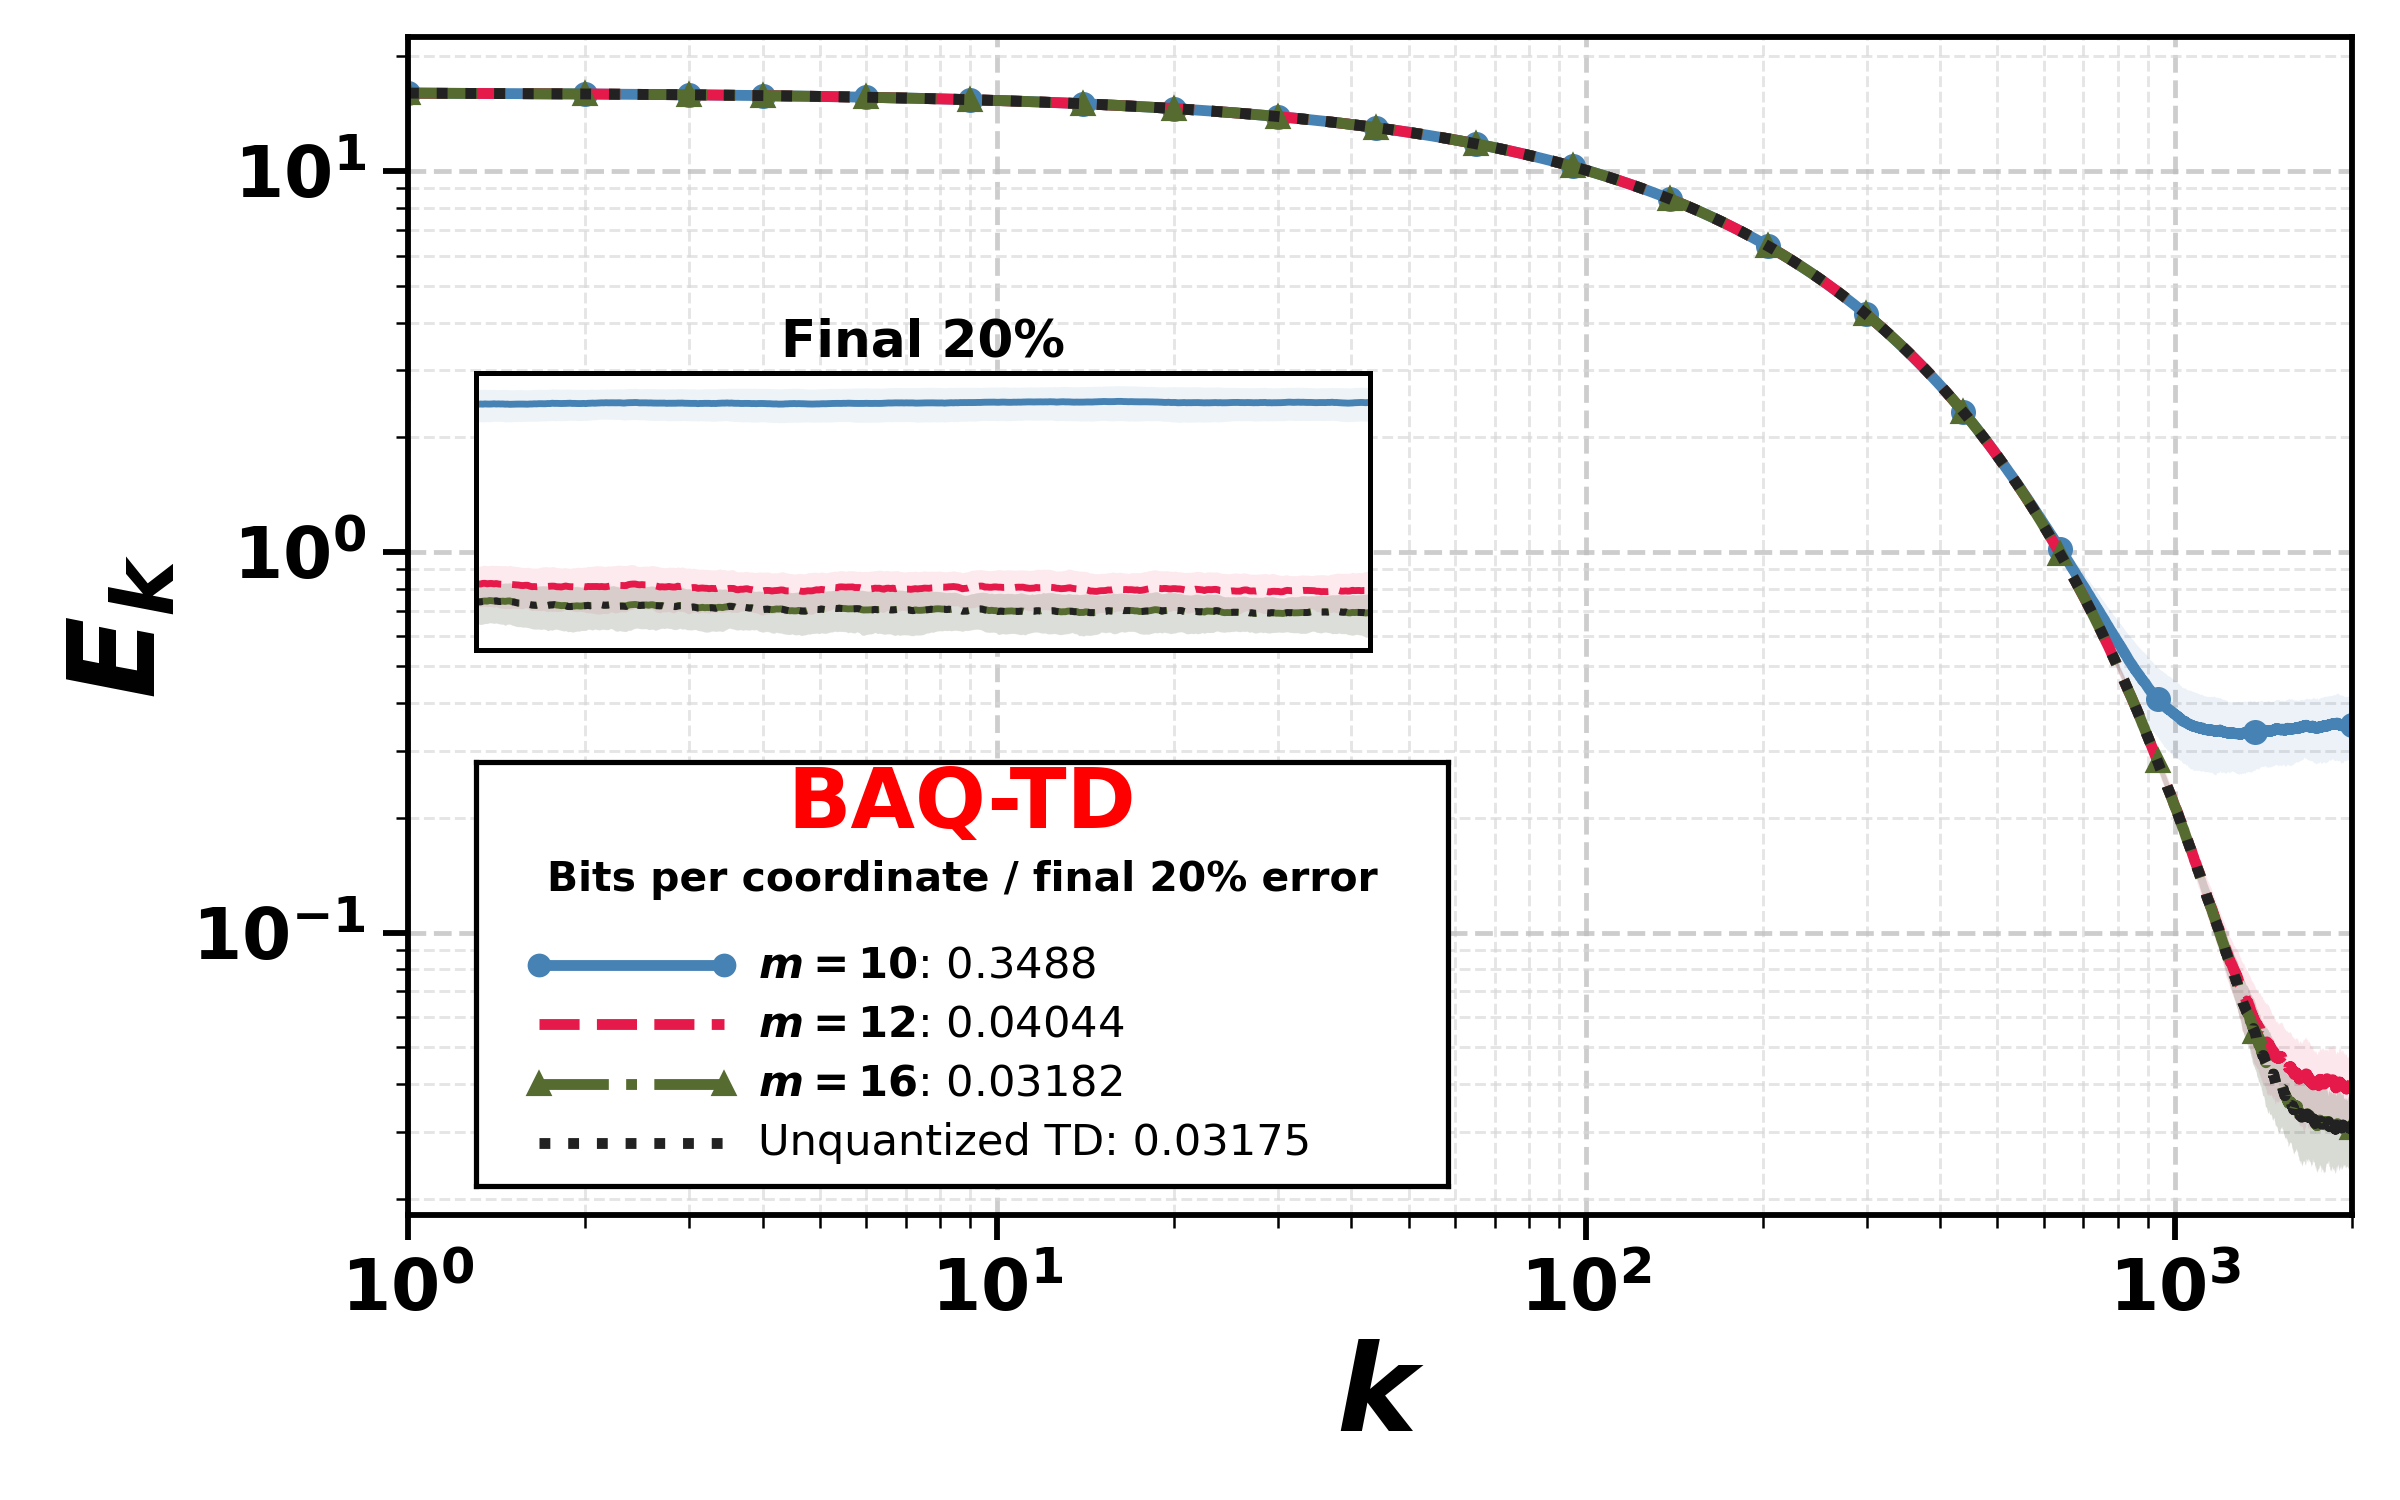

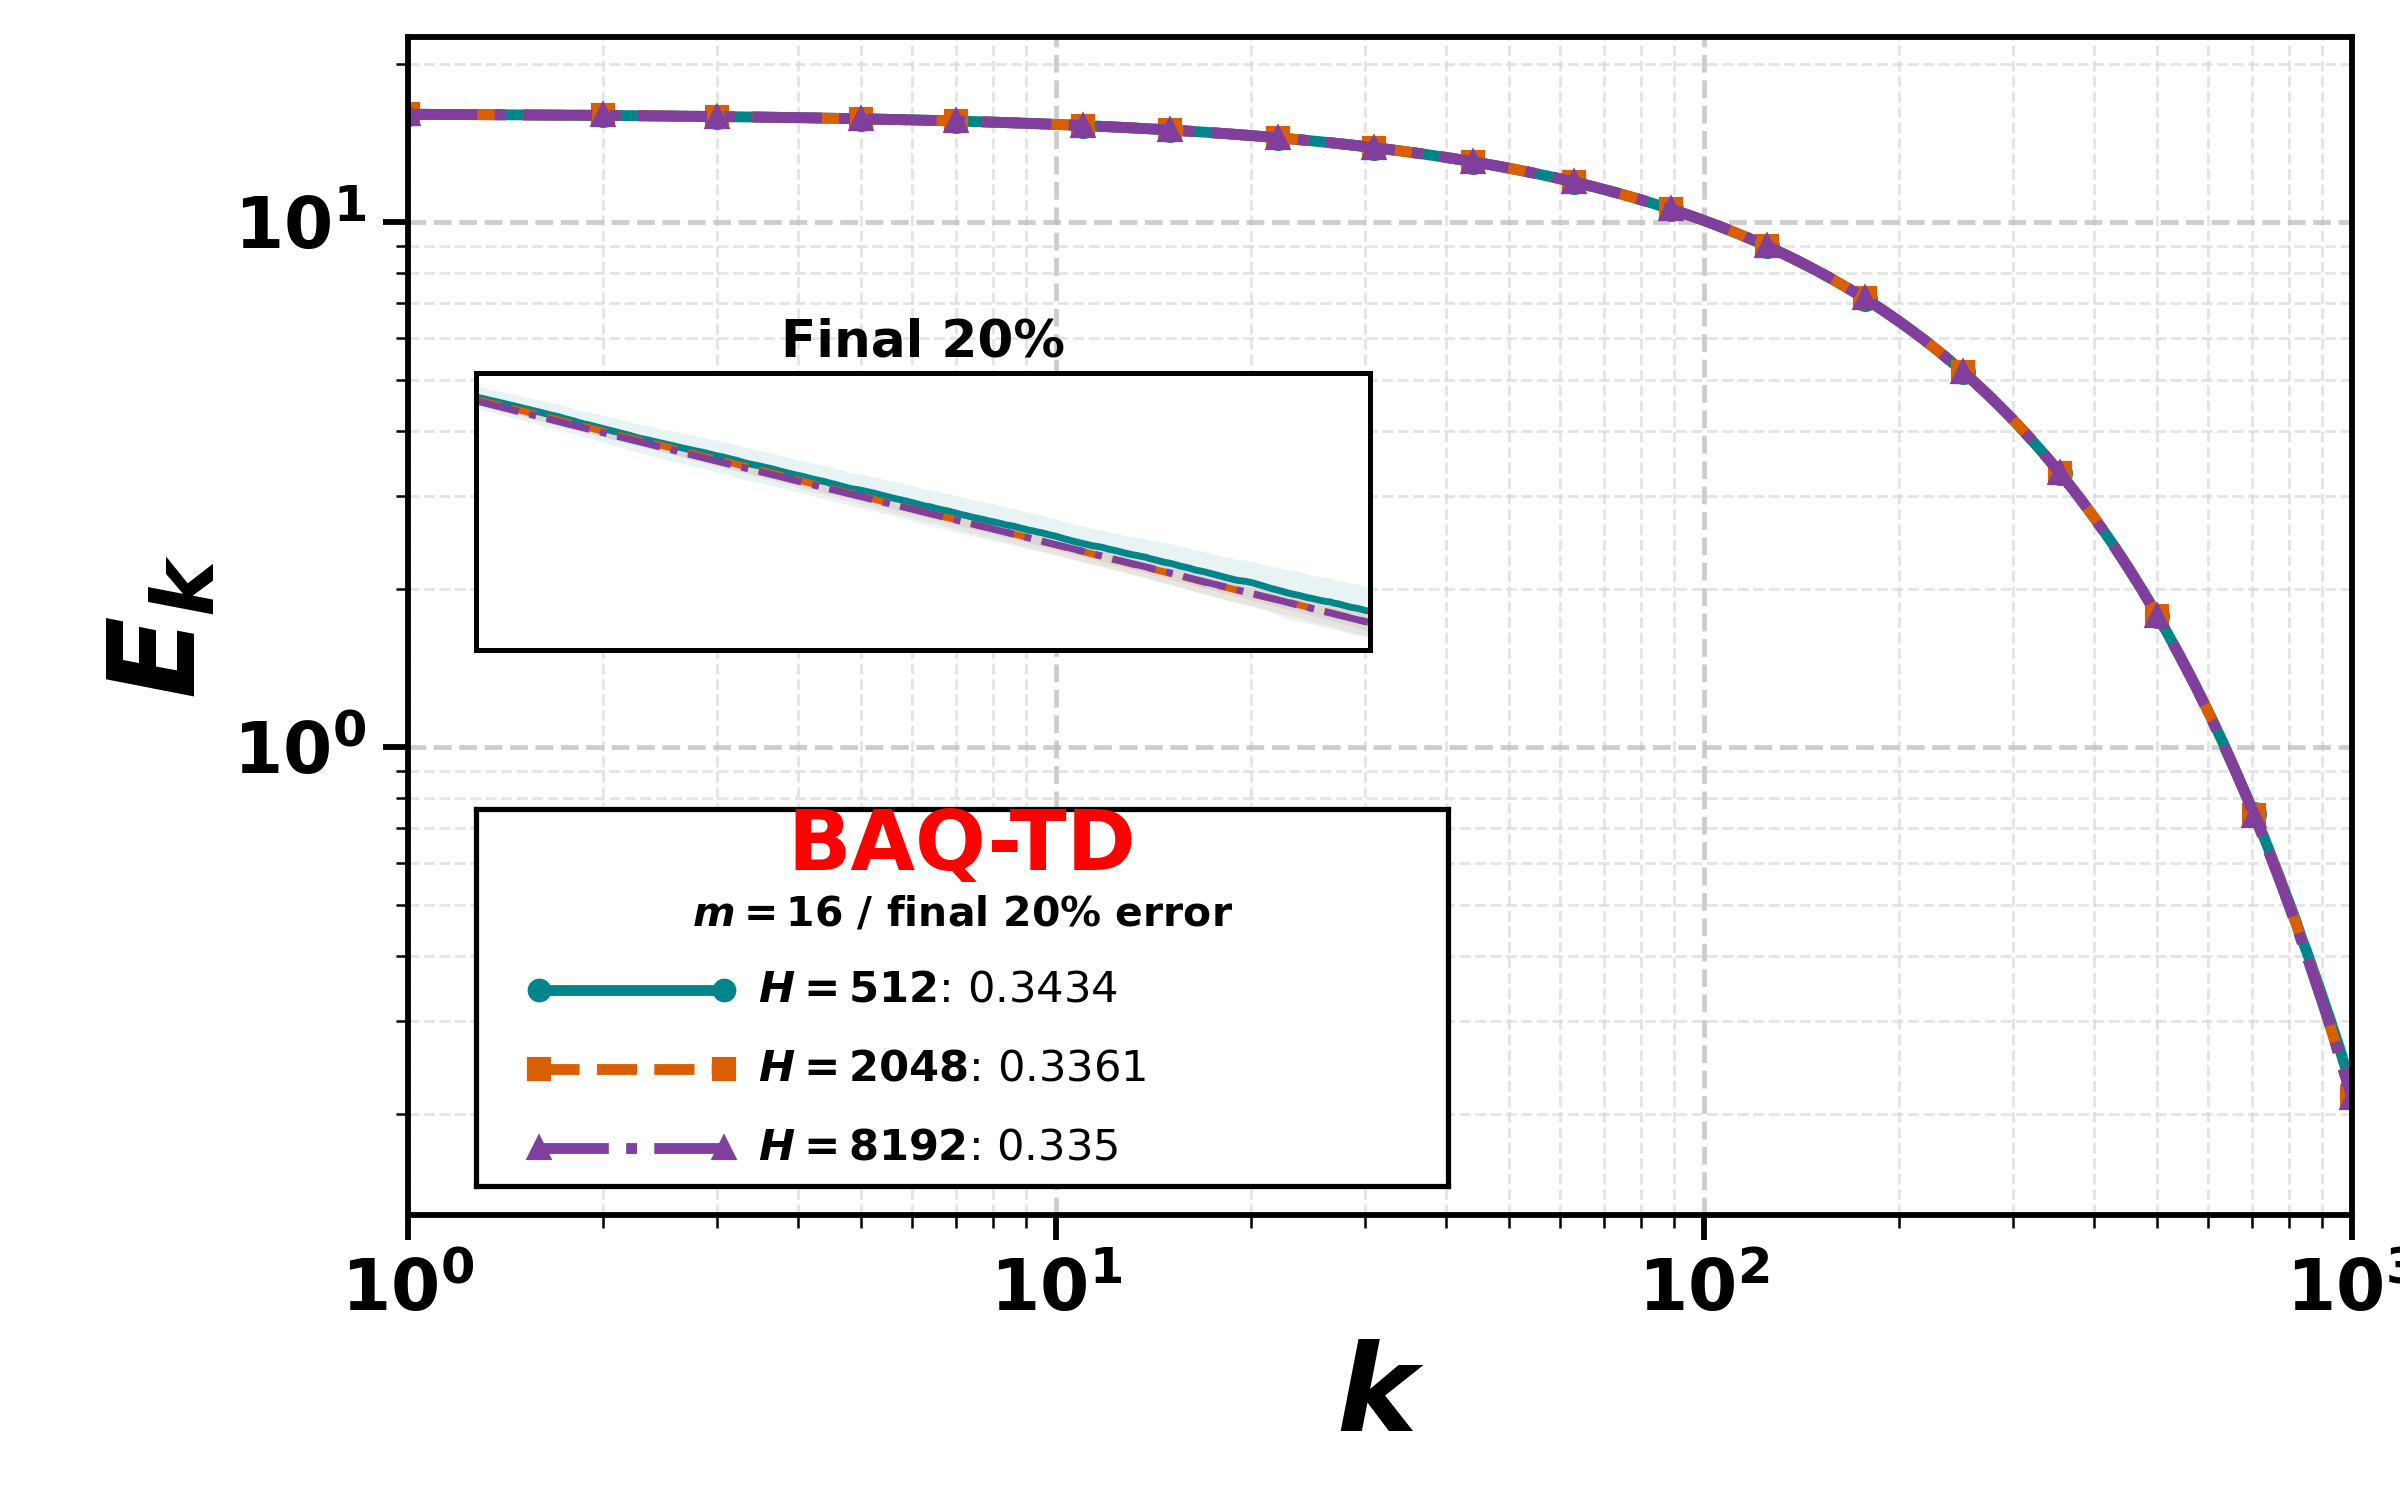

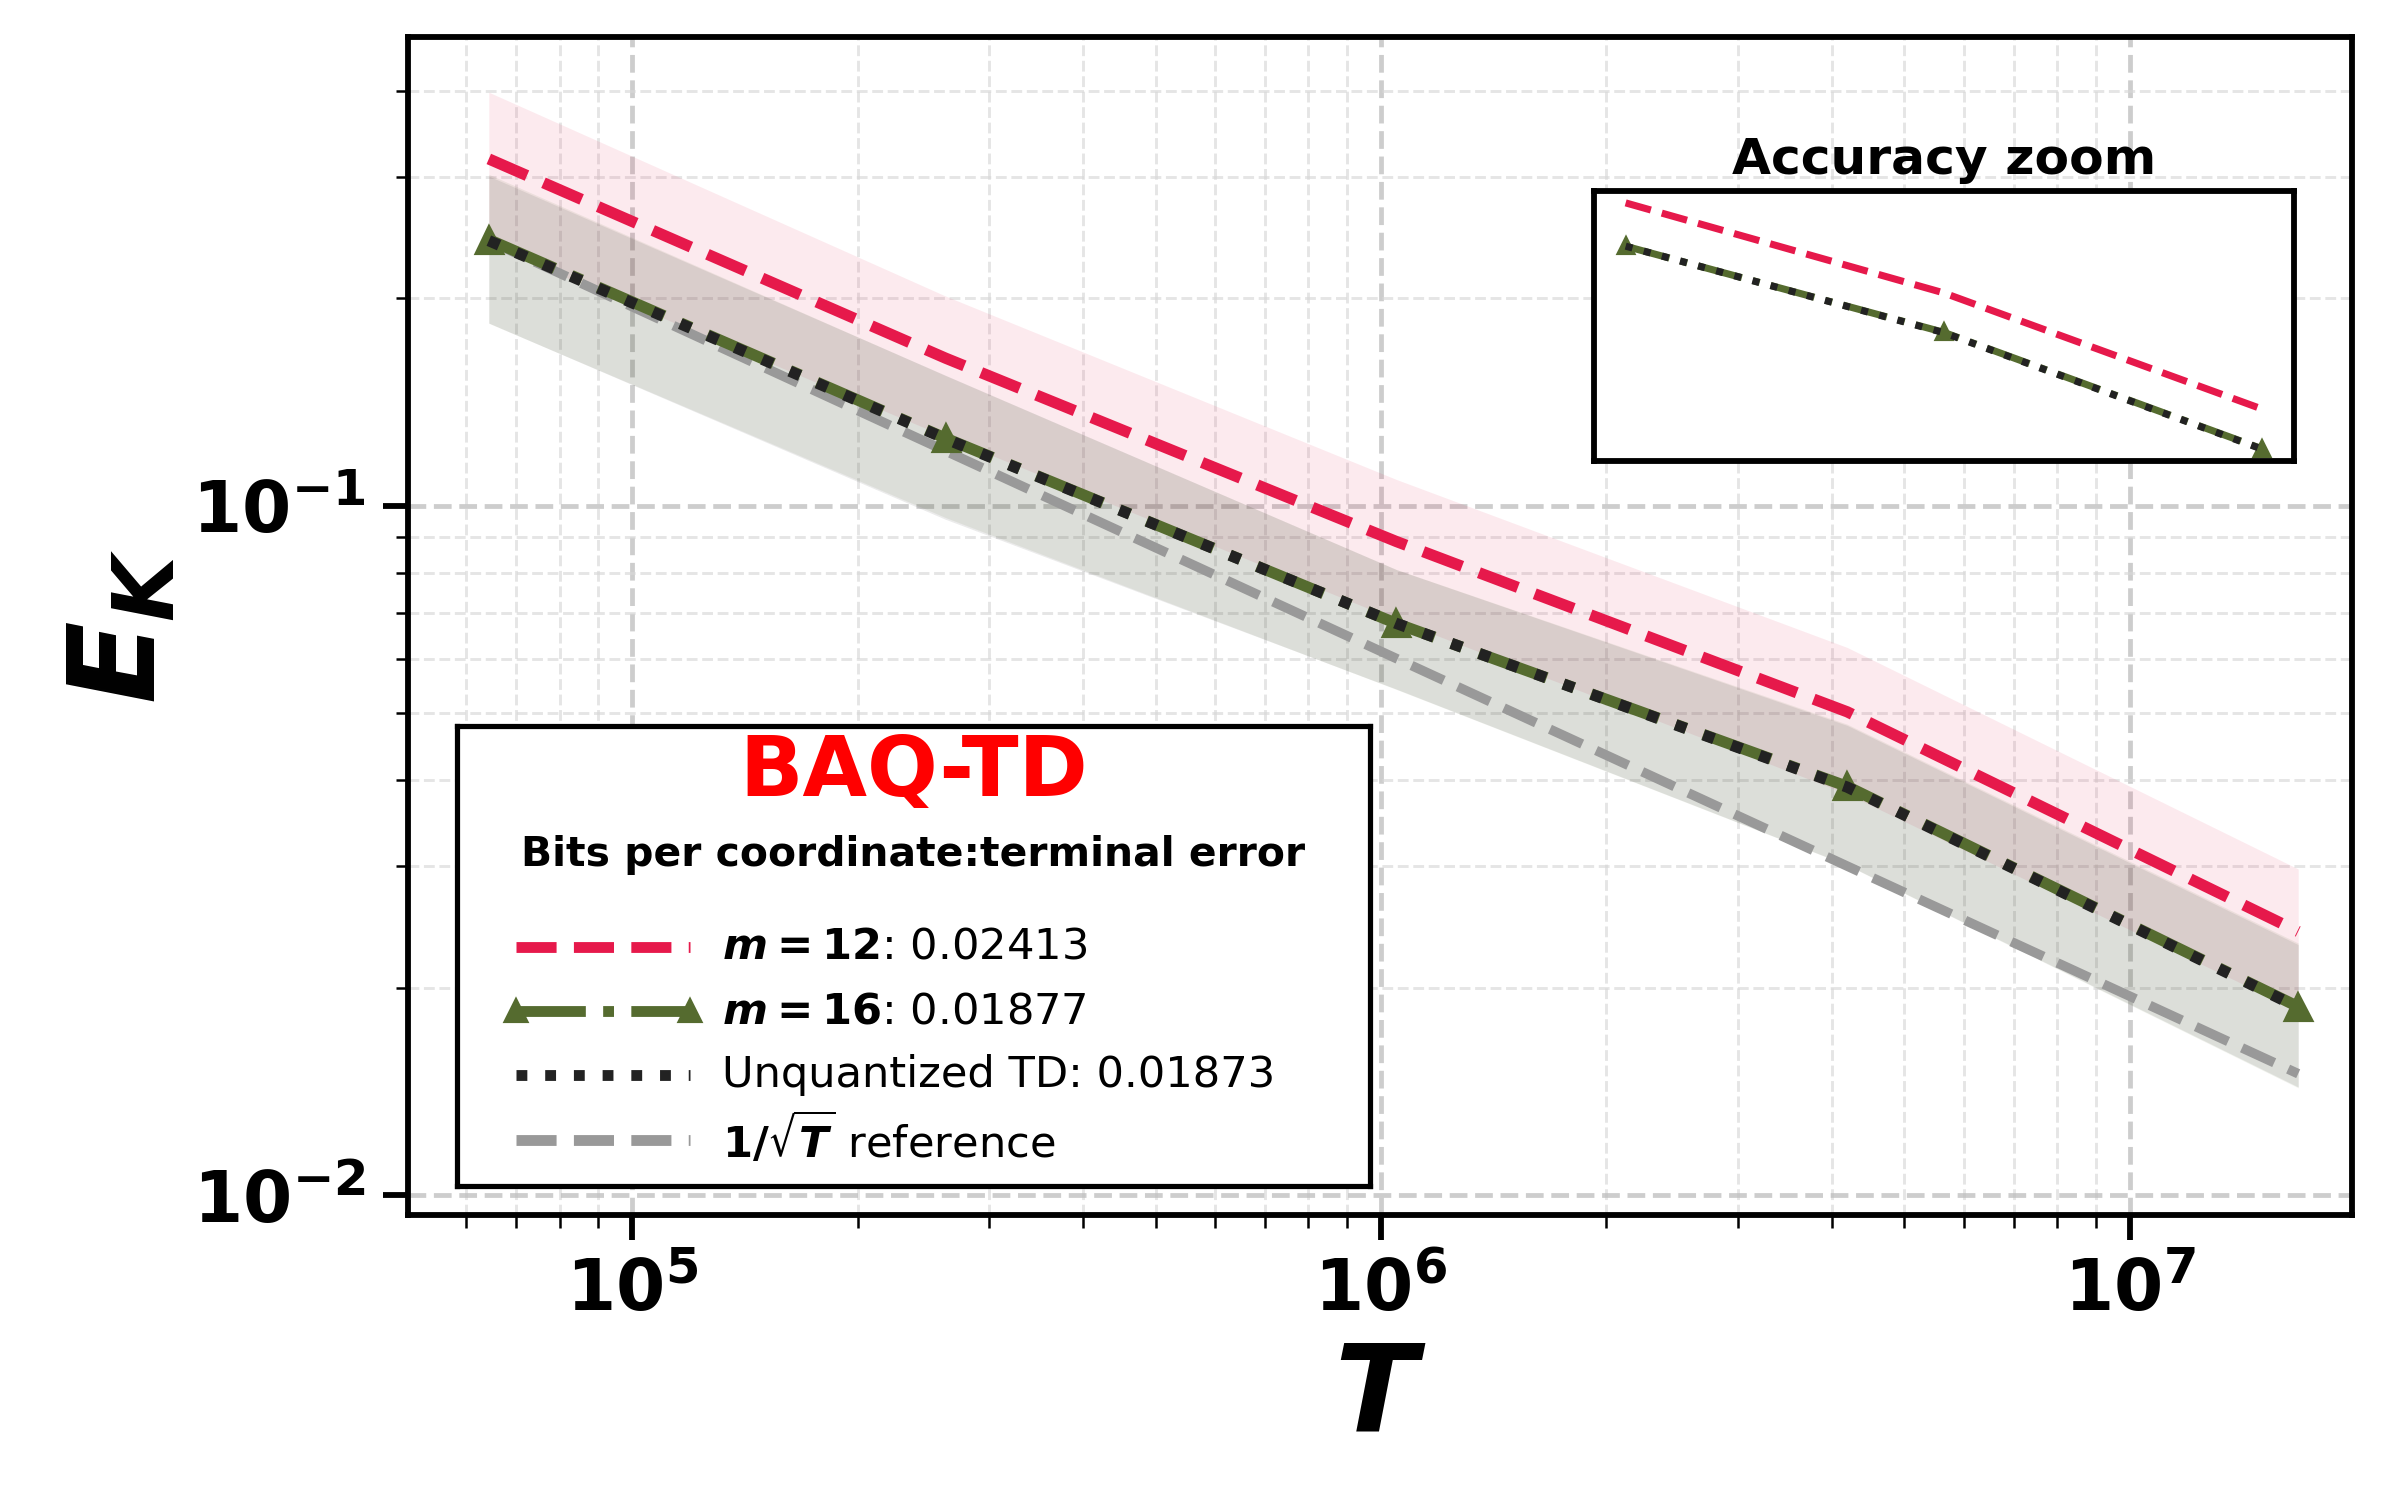

In [ ]:
from IPython.display import display, Image
for name in ("ECC-1", "ECC-2", "ECC-3"):
    display(Image(filename=str(OUT / f"{name}.png")))


## Download the output package
